In [ ]:
!pip install google-genai

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from datasets import load_dataset

ds = load_dataset("dinushiTJ/nz_hansard_classification_4096_tokens", split="train")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/9.98M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/2.63M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/851 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/213 [00:00<?, ? examples/s]

In [3]:
# def build_triplet_extraction_prompt(doc: str) -> str:
#     return f'''You are an expert in New Zealand Parliament Hansard analysis, specializing in creating high-quality semantic triplets for contrastive embedding model fine-tuning.

# OBJECTIVE: Extract semantic triplets (anchor, positive, negative) from the Hansard document to train an embedding model that distinguishes between Māori-related and non-Māori parliamentary content through deep semantic understanding.

# ---

# STEP 1: ANCHOR EXTRACTION

# Extract 3-6 anchor spans from the document.

# ANCHOR REQUIREMENTS:
# - EXACT verbatim quote from the document (no modifications)
# - 80-200 words in length
# - Semantically coherent and contextually complete
# - Contains substantive policy or legislative content
# - Avoids purely procedural text (e.g., "The House rose at...", "Motion agreed to")

# SELECTION STRATEGY:
# - Prioritize diverse policy domains across anchors
# - Balance between maori_origin and non_maori_origin examples
# - Choose spans with clear semantic boundaries
# - Prefer content-rich passages over formulaic statements

# ---

# STEP 2: LABEL ASSIGNMENT

# Assign ONE label per anchor:

# maori_origin - Content with PRIMARY focus on:
# - Māori people, communities, iwi, or hapū
# - Te Reo Māori language policy or education
# - Treaty of Waitangi obligations or settlements
# - Māori land rights, resources, or governance
# - Māori health, education, or social outcomes
# - Māori cultural practices or heritage
# - Māori-specific legislation or policy frameworks

# non_maori_origin - Content where:
# - Primary focus is on non-Māori policy domains
# - Māori references are incidental, comparative, or illustrative
# - Topic is general with no specific Māori dimension

# EDGE CASE GUIDANCE:
# - "All New Zealanders including Māori" → non_maori_origin
# - Brief mentions of "iwi consultation" in broader policy → non_maori_origin
# - Dedicated discussion of Māori-specific outcomes → maori_origin
# - When uncertain, default to non_maori_origin

# ---

# STEP 3: POSITIVE GENERATION

# For each anchor, generate ONE positive that is a semantic equivalent.

# POSITIVE REQUIREMENTS:
# - SAME label as anchor (critical for contrastive learning)
# - SAME core meaning, policy focus, and argumentation
# - Length within ±15% of anchor length
# - Maintains Hansard register and formality
# - Uses synonyms, restructuring, or perspective shifts

# TRANSFORMATION TECHNIQUES:
# - Lexical substitution: "funding" → "financial support"
# - Syntactic restructuring: active ↔ passive voice
# - Perspective shift: "Government must..." → "It is essential that..."
# - Elaboration or compression while preserving semantics
# - Reordering of clauses or arguments

# CRITICAL CONSTRAINTS:
# - Do NOT change Māori relevance level
# - Do NOT introduce new policy domains
# - Do NOT alter factual claims or positions
# - Do NOT use contradictory language

# ---

# STEP 4: NEGATIVE GENERATION

# For each anchor, generate ONE negative that provides semantic contrast.

# NEGATIVE REQUIREMENTS:
# - OPPOSITE label from anchor (maori_origin ↔ non_maori_origin)
# - SAME or closely related policy domain
# - 80-200 words in length
# - Semantically plausible and realistic Hansard content
# - Challenges model to distinguish beyond keywords

# CONTRAST STRATEGY:
# If anchor is maori_origin, negative should:
# - Discuss the same policy area (health, education, housing) without Māori focus
# - Address general population outcomes
# - Use similar terminology but different beneficiary groups

# If anchor is non_maori_origin, negative should:
# - Introduce specific Māori dimension to the same policy area
# - Discuss Treaty implications or Māori-specific outcomes
# - Reference Māori governance or cultural considerations

# QUALITY CRITERIA:
# - Avoids trivial keyword swaps ("Māori health" → "public health")
# - Maintains factual plausibility (no contradictions)
# - Requires contextual understanding to classify correctly
# - Tests model's semantic depth, not surface patterns

# ---

# DIFFICULTY ASSESSMENT

# Assess difficulty based on the ANCHOR text only:

# medium:
# - Māori relevance is explicit through clear terminology
# - Keywords or named entities strongly signal classification
# - A bag-of-words model would likely succeed
# - Examples: Direct mentions of "Treaty of Waitangi", "Te Reo Māori"

# hard:
# - Māori relevance is implicit or contextually dependent
# - Requires understanding of policy implications or beneficiaries
# - Keywords alone are insufficient or misleading
# - A bag-of-words model would struggle
# - Examples: Indirect references, policy impacts, subtle framing

# Default to hard when uncertain.

# ---

# OUTPUT FORMAT

# Return ONLY valid JSON with no preamble or explanation:

# {{
#   "triplets": [
#     {{
#       "anchor_label": "maori_origin",
#       "anchor_text": "<exact verbatim quote from document>",
#       "positive_text": "<semantically equivalent paraphrase with same label>",
#       "negative_label": "non_maori_origin",
#       "negative_text": "<contrastive example in same domain with opposite label>",
#       "difficulty": "hard",
#       "policy_domain": "Health policy",
#       "rationale": "Anchor focuses on Māori health outcomes under Treaty obligations; negative addresses general population health funding in same service area without Treaty or Māori-specific dimension."
#     }}
#   ]
# }}

# ---

# QUALITY CHECKLIST (verify before output)

# For each triplet:
# - Anchor is verbatim from document
# - Positive preserves anchor's label and core semantics
# - Negative has opposite label but related policy domain
# - All texts are 80-200 words (positive within ±15% of anchor)
# - Negative provides non-trivial semantic contrast
# - Difficulty reflects anchor's classification challenge
# - Rationale clearly explains the semantic contrast

# ---

# DOCUMENT:

# """
# {doc}
# """
# '''

In [4]:
import os
import json
from google import genai
from google.genai import types
import json


client = genai.Client(vertexai=True, project="gen-lang-client-0900489206", location="us-central1")

# def extract_triplets(text, model_name="gemini-2.5-flash", temperature=0.0, mime_type="application/json"):
#     prompt = build_triplet_extraction_prompt(text)

#     response = client.models.generate_content(
#         model=model_name,
#         contents=prompt,
#         config=types.GenerateContentConfig(
#             temperature=temperature,
#             response_mime_type=mime_type,
#         ),
#     )

#     return json.loads(response.text)


In [5]:
# import time

# def extract_triplets_with_retry(
#     text,
#     model_name="gemini-2.5-flash",
#     temperature=0.0,
#     mime_type="application/json",
#     max_retries=2
# ):
#     backoff_times = [30, 60]

#     for attempt in range(max_retries + 1):
#         try:
#             return extract_triplets(text=text, model_name=model_name, temperature=temperature, mime_type=mime_type)
#         except Exception as e:
#             if attempt < max_retries:
#                 wait = backoff_times[attempt] if len(backoff_times) < attempt else backoff_times[-1]
#                 print(f"⚠️ API error: {e}. Retrying in {wait}s...")
#                 time.sleep(wait)
#             else:
#                 print("❌ Failed after retries. Skipping.")
#                 return None


In [6]:
from google.colab import auth
auth.authenticate_user()

In [7]:
# !mkdir -p "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/embedding_ds"

In [8]:
import os
from tqdm.auto import tqdm
import json

# Initialize an empty list named processed_indices to keep track of successfully processed document indices.
processed_indices = []

# Define the output directory
output_directory = '/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/embedding_ds'

# Ensure the directory exists (though it was already created by a previous cell)
os.makedirs(output_directory, exist_ok=True)

In [9]:
# # Iterate through the 'ds' dataset using tqdm, accessing both the index (i) and the item (item) for each entry.
# for i, item in enumerate(tqdm(ds)):
#     # Inside the loop, extract the document content from item['HpsProceedingContent'].
#     document_text = item['HpsProceedingContent']

#     # Call extract_triplets_with_retry with the extracted document content as the text argument.
#     # Store the result in a variable, for example, extracted_data.
#     extracted_data = extract_triplets_with_retry(text=document_text, model_name="gemini-2.5-flash")

#     # Check if extracted_data is not None. If it contains valid data:
#     if extracted_data is not None:
#         # Construct the file path for saving the JSON.
#         # The path should be within '/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/embedding_ds'
#         # and the filename should be triplets_doc_{i}.json (where {i} is the current index).
#         file_name = f'triplets_doc_{i}.json'
#         output_path = os.path.join(output_directory, file_name)

#         # Open the constructed file path in write mode ('w').
#         # Use json.dump() to write the extracted_data dictionary to the file,
#         # ensuring to set indent=4 for readability.
#         with open(output_path, 'w') as f:
#             json.dump(extracted_data, f, indent=4)

#         # Append the current index i to the processed_indices list.
#         processed_indices.append(i)

# # After the loop, print the total number of documents for which triplets were successfully extracted and saved.
# print(f"Finished processing dataset. Total documents with triplets extracted and saved: {len(processed_indices)}")

In [10]:
def build_triplet_extraction_prompt(doc: str, doc_classification_label: str) -> str:
    return f'''You are an expert in New Zealand Parliament Hansard analysis, specializing in creating high-quality semantic triplets for contrastive embedding model fine-tuning.

OBJECTIVE: Extract semantic triplets (anchor, positive, negative) from the Hansard document to train an embedding model that distinguishes between Māori-related and non-Māori parliamentary content through deep semantic understanding.

The overall document is classified as: {doc_classification_label}. Use this context to guide your triplet extraction, especially in balancing maori_origin and non_maori_origin examples.

---

STEP 1: ANCHOR EXTRACTION

Extract 3-6 anchor spans from the document.

ANCHOR REQUIREMENTS:
- EXACT verbatim quote from the document (no modifications)
- 80-200 words in length
- Semantically coherent and contextually complete
- Contains substantive policy or legislative content
- Avoids purely procedural text (e.g., "The House rose at...", "Motion agreed to")

SELECTION STRATEGY:
- Prioritize diverse policy domains across anchors
- Balance between maori_origin and non_maori_origin examples
- Choose spans with clear semantic boundaries
- Prefer content-rich passages over formulaic statements

---

STEP 2: LABEL ASSIGNMENT

Assign ONE label per anchor:

maori_origin - Content with PRIMARY focus on:
- Māori people, communities, iwi, or hapū
- Te Reo Māori language policy or education
- Treaty of Waitangi obligations or settlements
- Māori land rights, resources, or governance
- Māori health, education, or social outcomes
- Māori cultural practices or heritage
- Māori-specific legislation or policy frameworks

non_maori_origin - Content where:
- Primary focus is on non-Māori policy domains
- Māori references are incidental, comparative, or illustrative
- Topic is general with no specific Māori dimension

EDGE CASE GUIDANCE:
- "All New Zealanders including Māori" → non_maori_origin
- Brief mentions of "iwi consultation" in broader policy → non_maori_origin
- Dedicated discussion of Māori-specific outcomes → maori_origin
- When uncertain, default to non_maori_origin

---

STEP 3: POSITIVE GENERATION

For each anchor, generate ONE positive that is a semantic equivalent.

POSITIVE REQUIREMENTS:
- SAME label as anchor (critical for contrastive learning)
- SAME core meaning, policy focus, and argumentation
- Length within ±15% of anchor length
- Maintains Hansard register and formality
- Uses synonyms, restructuring, or perspective shifts

TRANSFORMATION TECHNIQUES:
- Lexical substitution: "funding" → "financial support"
- Syntactic restructuring: active ↔ passive voice
- Perspective shift: "Government must..." → "It is essential that..."
- Elaboration or compression while preserving semantics
- Reordering of clauses or arguments

CRITICAL CONSTRAINTS:
- Do NOT change Māori relevance level
- Do NOT introduce new policy domains
- Do NOT alter factual claims or positions
- Do NOT use contradictory language

---

STEP 4: NEGATIVE GENERATION

For each anchor, generate ONE negative that provides semantic contrast.

NEGATIVE REQUIREMENTS:
- OPPOSITE label from anchor (maori_origin ↔ non_maori_origin)
- SAME or closely related policy domain
- 80-200 words in length
- Semantically plausible and realistic Hansard content
- Challenges model to distinguish beyond keywords

CONTRAST STRATEGY:
If anchor is maori_origin, negative should:
- Discuss the same policy area (health, education, housing) without Māori focus
- Address general population outcomes
- Use similar terminology but different beneficiary groups

If anchor is non_maori_origin, negative should:
- Introduce specific Māori dimension to the same policy area
- Discuss Treaty implications or Māori-specific outcomes
- Reference Māori governance or cultural considerations

QUALITY CRITERIA:
- Avoids trivial keyword swaps ("Māori health" → "public health")
- Maintains factual plausibility (no contradictions)
- Requires contextual understanding to classify correctly
- Tests model's semantic depth, not surface patterns

---

DIFFICULTY ASSESSMENT

Assess difficulty based on the ANCHOR text only:

medium:
- Māori relevance is explicit through clear terminology
- Keywords or named entities strongly signal classification
- A bag-of-words model would likely succeed
- Examples: Direct mentions of "Treaty of Waitangi", "Te Reo Māori"

hard:
- Māori relevance is implicit or contextually dependent
- Requires understanding of policy implications or beneficiaries
- Keywords alone are insufficient or misleading
- A bag-of-words model would struggle
- Examples: Indirect references, policy impacts, subtle framing

Default to hard when uncertain.

---

OUTPUT FORMAT

Return ONLY valid JSON with no preamble or explanation:

{{
  "triplets": [
    {{
      "anchor_label": "maori_origin",
      "anchor_text": "<exact verbatim quote from document>",
      "positive_text": "<semantically equivalent paraphrase with same label>",
      "negative_label": "non_maori_origin",
      "negative_text": "<contrastive example in same domain with opposite label>",
      "difficulty": "hard",
      "policy_domain": "Health policy",
      "rationale": "Anchor focuses on Māori health outcomes under Treaty obligations; negative addresses general population health funding in same service area without Treaty or Māori-specific dimension."
    }}
  ]
}}

---

QUALITY CHECKLIST (verify before output)

For each triplet:
- Anchor is verbatim from document
- Positive preserves anchor's label and core semantics
- Negative has opposite label but related policy domain
- All texts are 80-200 words (positive within ±15% of anchor)
- Negative provides non-trivial semantic contrast
- Difficulty reflects anchor's classification challenge
- Rationale clearly explains the semantic contrast

---

DOCUMENT:

"""
{doc}
"""'''

import json
import time


def extract_triplets(text, doc_classification_label, model_name="gemini-2.5-flash", temperature=0.0, mime_type="application/json"):
    prompt = build_triplet_extraction_prompt(text, doc_classification_label)

    response = client.models.generate_content(
        model=model_name,
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=temperature,
            response_mime_type=mime_type,
        ),
    )

    return json.loads(response.text)

def extract_triplets_with_retry(
    text,
    doc_classification_label,
    model_name="gemini-2.5-flash",
    temperature=0.0,
    mime_type="application/json",
    max_retries=2
):
    backoff_times = [30, 60]

    for attempt in range(max_retries + 1):
        try:
            return extract_triplets(text=text, doc_classification_label=doc_classification_label, model_name=model_name, temperature=temperature, mime_type=mime_type)
        except Exception as e:
            if attempt < max_retries:
                wait = backoff_times[attempt] if len(backoff_times) < attempt else backoff_times[-1]
                print(f"⚠️ API error: {e}. Retrying in {wait}s...")
                time.sleep(wait)
            else:
                print("❌ Failed after retries. Skipping.")
                return None


In [11]:
existing_files = os.listdir(output_directory)
start_idx = len(existing_files)
print(start_idx)

720


In [12]:
processed_files = []

for i in tqdm(range(start_idx, len(ds))):
    item = ds[i]

    # Skip already processed files
    new_file_name = f'triplets_doc_{i}.json'

    if new_file_name in processed_files or new_file_name in existing_files:
        continue

    document_text = item['HpsProceedingContent']
    doc_classification_label = item['classification_label'] # Extract the classification label

    extracted_data = extract_triplets_with_retry(text=document_text, doc_classification_label=doc_classification_label, model_name="gemini-2.5-flash")

    if extracted_data is not None:
        output_path = os.path.join(output_directory, new_file_name)

        with open(output_path, 'w') as f:
            json.dump(extracted_data, f, indent=4)

        processed_files.append(new_file_name)

print(f"Finished processing dataset. Total documents with triplets extracted and saved: {len(processed_indices)}")

  0%|          | 0/131 [00:00<?, ?it/s]

Finished processing dataset. Total documents with triplets extracted and saved: 0


In [13]:
import os
import json
import pandas as pd
from tqdm import tqdm


In [16]:
from tqdm import tqdm
import os, json

DATA_DIR = "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/embedding_ds"

all_triplets = []

files = [f for f in os.listdir(DATA_DIR) if f.endswith(".json")]

pbar = tqdm(files)

for fname in pbar:
    pbar.set_description(f"Processing {fname}")

    file_path = os.path.join(DATA_DIR, fname)

    with open(file_path, "r") as f:
        data = json.load(f)

    if isinstance(data, list):
        data = {"triplets": data}

    triplets = data.get("triplets", [])

    for t in triplets:
        t["_filename"] = fname
        all_triplets.append(t)

print(f"Total triplets collected: {len(all_triplets)}")


Processing triplets_doc_850.json: 100%|██████████| 851/851 [00:11<00:00, 76.40it/s] 

Total triplets collected: 3272


In [17]:
df = pd.DataFrame(all_triplets)


In [18]:
df["anchor_label"] = df["anchor_label"].astype("category")
df["negative_label"] = df["negative_label"].astype("category")
df["difficulty"] = df["difficulty"].astype("category")
df["policy_domain"] = df["policy_domain"].astype("category")


In [19]:
df.info()
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3272 entries, 0 to 3271
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   anchor_label    3272 non-null   category
 1   anchor_text     3272 non-null   object  
 2   positive_text   3272 non-null   object  
 3   negative_label  3272 non-null   category
 4   negative_text   3272 non-null   object  
 5   difficulty      3272 non-null   category
 6   policy_domain   3272 non-null   category
 7   rationale       3272 non-null   object  
 8   _filename       3272 non-null   object  
dtypes: category(4), object(5)
memory usage: 231.8+ KB


,anchor_label,anchor_text,positive_text,negative_label,negative_text,difficulty,policy_domain,rationale,_filename
0,non_maori_origin,One of the key purposes that they do is they a...,A primary objective of these legislative chang...,maori_origin,A critical aspect of ensuring justice for all ...,hard,Justice/Court Security,Anchor discusses general court security powers...,triplets_doc_0.json
1,non_maori_origin,The most interesting part of the Tribunals Pow...,Perhaps the most compelling aspect of the Trib...,maori_origin,A critical concern within the human rights fra...,hard,Justice/Human Rights/Tribunal Efficiency,Anchor discusses the general backlog and effic...,triplets_doc_0.json
2,non_maori_origin,The proposed changes should be commended becau...,These legislative amendments deserve praise fo...,maori_origin,While enhancing the efficiency of general trib...,hard,Justice/Tribunal Efficiency/Dispute Resolution,Anchor discusses general improvements in tribu...,triplets_doc_0.json
3,non_maori_origin,I just want to quickly mention one in my time ...,I wish to briefly highlight a specific provisi...,maori_origin,While increasing the Disputes Tribunal monetar...,hard,Justice/Dispute Resolution/Access to Justice,Anchor discusses a general increase in the Dis...,triplets_doc_0.json
4,non_maori_origin,The Local Electoral Matters Bill amends and mo...,"This legislation, the Local Electoral Matters ...",maori_origin,The proposed amendments to electoral law are c...,medium,"Electoral reform, Civic participation",Anchor focuses on general modernization of ele...,triplets_doc_1.json


In [21]:
doc_labels = (
    df.groupby("_filename")["anchor_label"]
      .agg(lambda x: x.value_counts().idxmax())
)


In [22]:
from sklearn.model_selection import train_test_split

train_docs, val_docs = train_test_split(
    doc_labels.index,
    test_size=0.15,
    random_state=42,
    stratify=doc_labels.values
)


In [24]:
train_df = df[df["_filename"].isin(train_docs)]
val_df = df[df["_filename"].isin(val_docs)]


In [32]:
from datasets import Dataset, DatasetDict

train_ds = Dataset.from_pandas(train_df, preserve_index=False)
val_ds = Dataset.from_pandas(val_df, preserve_index=False)

dataset = DatasetDict({
    "train": train_ds,
    "test": val_ds
})


In [33]:
dataset
dataset["train"][0]


{'anchor_label': 'non_maori_origin',
 'anchor_text': 'One of the key purposes that they do is they amend the Court Security Act 1999, and some of the key things that they do there is they extend the powers of court security officers to deny entry, to remove and detain people who possess illegal drugs or who act threateningly or abusively or who commit minor crimes on court premises. I think this is an important part of these pieces of legislation, because it gives some clarity and it gives some particular powers to court security officers to exercise those powers when they are in the court, and it allows them to have the discretion not only when the court is in hearing but even when they’re not directed to take action against people who may come into the courts with different paraphernalia or with drugs, and to ensure that those matters are dealt with appropriately and quickly. It also just changes the definition of the court and clarifies what the court is and where they are able to e

In [34]:
from datasets import ClassLabel

label_names = sorted(train_df["anchor_label"].unique())

dataset = dataset.cast_column(
    "anchor_label",
    ClassLabel(names=label_names)
)

dataset = dataset.cast_column(
    "negative_label",
    ClassLabel(names=label_names)
)

dataset = dataset.cast_column(
    "difficulty",
    ClassLabel(names=sorted(train_df["difficulty"].unique()))
)



Casting the dataset:   0%|          | 0/2770 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/502 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/2770 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/502 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/2770 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/502 [00:00<?, ? examples/s]

In [35]:
dataset["train"][0]

{'anchor_label': 1,
 'anchor_text': 'One of the key purposes that they do is they amend the Court Security Act 1999, and some of the key things that they do there is they extend the powers of court security officers to deny entry, to remove and detain people who possess illegal drugs or who act threateningly or abusively or who commit minor crimes on court premises. I think this is an important part of these pieces of legislation, because it gives some clarity and it gives some particular powers to court security officers to exercise those powers when they are in the court, and it allows them to have the discretion not only when the court is in hearing but even when they’re not directed to take action against people who may come into the courts with different paraphernalia or with drugs, and to ensure that those matters are dealt with appropriately and quickly. It also just changes the definition of the court and clarifies what the court is and where they are able to exercise those pow

In [36]:
dataset["test"][0]

{'anchor_label': 1,
 'anchor_text': 'The Local Electoral Matters Bill amends and modernises two pieces of legislation and is one component of a broader effort to improve civic participation in local government. As New Zealanders are using postal services less, this creates increasing challenges for local authorities to deliver postal voting effectively and affordably. Innovation is required to adapt to the changing public expectations about how people wish to engage with central and local government. As a brief summary, the bill comprises two parts. Part 1 amends the Local Electoral Act 2001 to make explicit provision for local authorities to conduct trials of new voting methods. In particular, the bill allows a new voting method to be trialled with a subset of voters within a local election, giving local authorities more options to manage risks when they’re designing trials. The bill also makes important improvements to the contingency mechanisms for local elections in the event that 

In [37]:
# keep_cols = [
#     "anchor_text",
#     "positive_text",
#     "negative_text",
#     "anchor_label",
#     "negative_label",
#     "difficulty",
#     "policy_domain"
# ]

# dataset = dataset.remove_columns(
#     [c for c in dataset["train"].column_names if c not in keep_cols]
# )


In [38]:
dataset.save_to_disk(
    "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/nz_hansard_triplets"
)



Saving the dataset (0/1 shards):   0%|          | 0/2770 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/502 [00:00<?, ? examples/s]

In [39]:
from huggingface_hub import login
from google.colab import userdata

login(token=userdata.get('DUSH_HFT'))

In [40]:
dataset.push_to_hub("dinushiTJ/nz-hansard-triplets")

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/3 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  12%|#2        |  525kB / 4.28MB            

...

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  67%|######7   |  526kB /  784kB            

CommitInfo(commit_url='https://huggingface.co/datasets/dinushiTJ/nz-hansard-triplets/commit/f9d1f781ce2995eedb0d09b933f87bfb8230faf5', commit_message='Upload dataset', commit_description='', oid='f9d1f781ce2995eedb0d09b933f87bfb8230faf5', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/dinushiTJ/nz-hansard-triplets', endpoint='https://huggingface.co', repo_type='dataset', repo_id='dinushiTJ/nz-hansard-triplets'), pr_revision=None, pr_num=None)

In [41]:
from datasets import load_dataset

ds = load_dataset("dinushiTJ/nz-hansard-triplets")

ds["train"].features
ds["test"].features

README.md:   0%|          | 0.00/947 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/4.28M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/784k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2770 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/502 [00:00<?, ? examples/s]

{'anchor_label': ClassLabel(names=['maori_origin', 'non_maori_origin']),
 'anchor_text': Value('string'),
 'positive_text': Value('string'),
 'negative_label': ClassLabel(names=['maori_origin', 'non_maori_origin']),
 'negative_text': Value('string'),
 'difficulty': ClassLabel(names=['hard', 'medium']),
 'policy_domain': Value('string'),
 'rationale': Value('string'),
 '_filename': Value('string')}

In [42]:
print("Train set label distribution:")
print(dataset["train"].to_pandas()["anchor_label"].value_counts())

print("\nTest set label distribution:")
print(dataset["test"].to_pandas()["anchor_label"].value_counts())

Train set label distribution:
anchor_label
1    2410
0     360
Name: count, dtype: int64

Test set label distribution:
anchor_label
1    424
0     78
Name: count, dtype: int64


/tmp/ipython-input-3102281804.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=train_label_counts.index, y=train_label_counts.values, ax=axes[0], palette='viridis')
/tmp/ipython-input-3102281804.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=test_label_counts.index, y=test_label_counts.values, ax=axes[1], palette='magma')


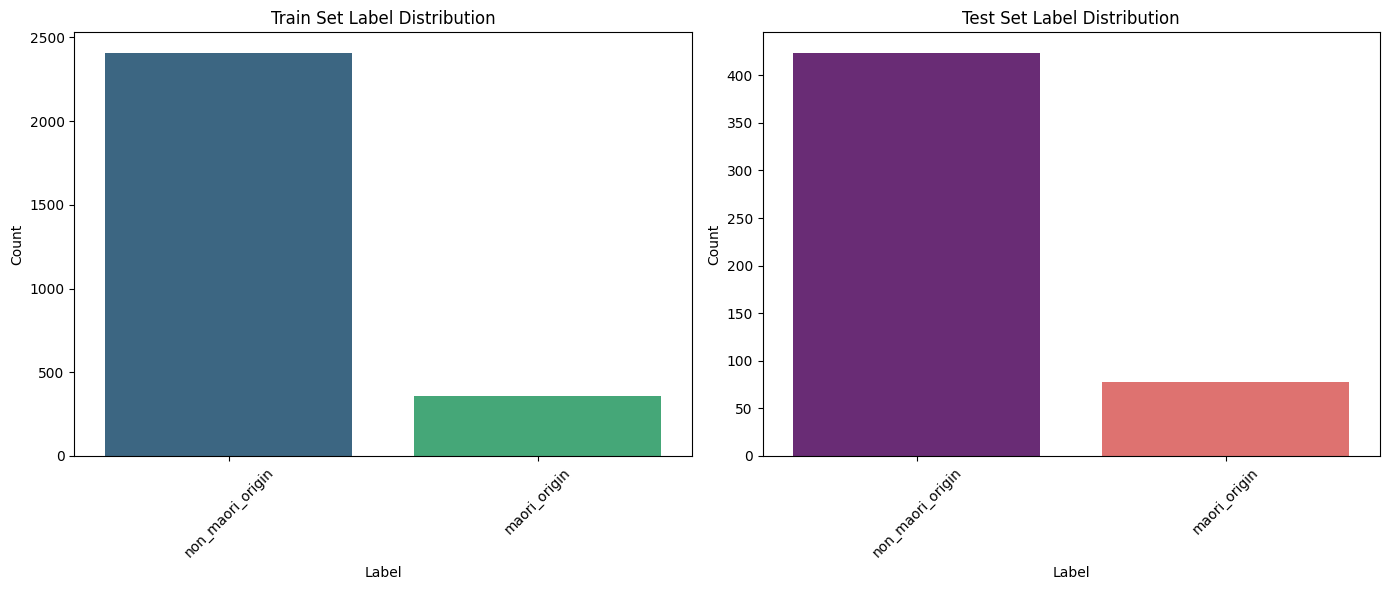

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get value counts for train and test sets
train_label_counts = dataset["train"].to_pandas()["anchor_label"].value_counts().rename(index={0: 'maori_origin', 1: 'non_maori_origin'})
test_label_counts = dataset["test"].to_pandas()["anchor_label"].value_counts().rename(index={0: 'maori_origin', 1: 'non_maori_origin'})

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Bar chart for Train set
sns.barplot(x=train_label_counts.index, y=train_label_counts.values, ax=axes[0], palette='viridis')
axes[0].set_title('Train Set Label Distribution')
axes[0].set_xlabel('Label')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Bar chart for Test set
sns.barplot(x=test_label_counts.index, y=test_label_counts.values, ax=axes[1], palette='magma')
axes[1].set_title('Test Set Label Distribution')
axes[1].set_xlabel('Label')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()